# Euclid DR1 galaxy morphology: Zoobot vote fractions in the MER catalogue

<br>

<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) Pedro Mas Buitrago and David O'Ryan, 2026.

This file is subject to the terms and conditions defined in file `LICENSE.txt`, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file `LICENSE.txt`.

</div>

**Last modified:** 10.11.2026

**Authors:** Pedro Mas Buitrago and David O'Ryan

**Notebook summary**

This notebook shows how to access and interpret the visual morphology measurements included in the Euclid DR1 MER catalogue. These measurements are produced by [Zoobot](https://github.com/mwalmsley/zoobot), a deep learning foundation model for galaxy morphology, fine-tuned on classifications of _Euclid_ images provided by [Galaxy Zoo](https://www.zooniverse.org/) volunteers. Volunteers answer a tree of questions (e.g., _"Is this galaxy smooth or featured?"_, _"Does it have spiral arms?"_), where the next question depends on the previous answer. For each galaxy, Zoobot predicts how volunteers would vote on every question of the tree. Rather than a single number per answer, Zoobot predicts a probability distribution for the votes, and the parameters of that distribution are the morphology columns provided in the MER catalogue (see below).

In this tutorial, you will learn how to:

1. Understand the decision tree and how it maps onto the morphology columns of the MER catalogue.
2. Retrieve the morphology columns (Dirichlet concentrations) from the MER catalogue using Astroquery and convert them into vote fractions.
3. Use the smooth / featured vote fractions to select and inspect galaxies.
4. Install Zoobot to apply or adapt the models to your own images.

**From Dirichlet concentrations to vote fractions**

The MER catalogue does not store vote fractions directly. For each question, Zoobot predicts the parameters of a [Dirichlet distribution](https://en.wikipedia.org/wiki/Dirichlet_distribution) that describes the expected distribution of volunteer votes across its answers ([Walmsley et al. 2022](https://scixplorer.org/abs/2022MNRAS.509.3966W/abstract)). The catalogue provides these **Dirichlet concentrations**, $\alpha_i > 0$, one per answer.

For a question with answers $i = 1, \dots, N$, the expected **vote fraction** of answer $i$ is the mean of the Dirichlet distribution:

$$
f_i = \frac{\alpha_i}{\sum_{j=1}^{N} \alpha_j}
$$

where the sum runs **only over the answers of that same question**. For example, for the first question of the tree:

$$
f_{\rm smooth} = \frac{\alpha_{\rm smooth}}{\alpha_{\rm smooth} + \alpha_{\rm featured\text{-}or\text{-}disk} + \alpha_{\rm problem}}
$$

The total concentration $\alpha_0 = \sum_j \alpha_j$ also carries information: for the same vote fractions, a larger $\alpha_0$ means a narrower distribution, i.e. a more confident prediction.

**A few things to keep in mind about the Zoobot measurements:**

* For Euclid DR1, Zoobot measurements are only provided for extended galaxies, with a ``segmentation_area`` (parameter given by the MER catalogue) greater than 1200 px.
* By construction, each vote fraction lies between 0 and 1, and the fractions of all the answers to a given question add up to 1.
* Zoobot provides predictions for **every** question for **every** galaxy, even for questions that a volunteer would never have been asked for that galaxy (e.g., the spiral-arms question for a smooth galaxy). Answers to questions deeper in the tree should therefore be interpreted together with the answers to the questions that lead to them.
* There is no unique threshold to turn vote fractions into classes: the threshold choice sets the balance between purity and completeness of the selected sample and should be adapted to each science case.

**Useful links:**

* [Euclid Collaboration: Walmsley et al. 2026 - Q1 visual morphology catalogue](https://scixplorer.org/abs/2026A%26A...711A...9E/abstract)
* [Zoobot GitHub repository](https://github.com/mwalmsley/zoobot)
* [Zoobot documentation](https://zoobot.readthedocs.io/)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/data-release-dr1)
* [Euclid DR1 data product description](https://www.cosmos.esa.int/documents/10647/12245842/DR1-memo_260922.pdf/3d879dc6-d5e0-9125-54a7-f68d1b4971d8?t=1790090418174)
* [Euclid MER catalogues](https://euclid.dataspace.esa.int/internal-archive-help/Catalogues.html)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)

**Key TAP tables:**

The morphology columns are part of the MER catalogue, so they can be retrieved together with any other MER measurement (positions, fluxes, sizes, flags, ...) with a single [ADQL](https://www.ivoa.net/documents/ADQL/20231215/) query, without the need of a cross-match.

**Running the notebook:** 

* This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. 
* The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.
* Zoobot is **not** needed to explore the morphology columns: Sections 1-3 only use the catalogue. Section 4 explains how to install Zoobot for users who want to run the models themselves.

**Version:**

* v1: First version, prepared for Euclid DR1.
***

In [2]:
from astroquery.esa.euclid.core import EuclidClass
from astropy import wcs
import pandas as pd
import numpy as np
import astropy.units as u
from astropy.nddata.utils import Cutout2D
from astropy.coordinates import SkyCoord
from astroquery.simbad import Simbad
from astropy.table import Table
import seaborn as sns
import getpass

from astropy.io import fits
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from astropy.visualization import (
    astropy_mpl_style,
    ImageNormalize,
    PercentileInterval,
    AsinhStretch,
    LogStretch,
)

plt.style.use(astropy_mpl_style)
import os

### Choosing the archive environment

In [3]:
# Choosing the archive environment
env = "PDR"  # Can be changed to "PDR" when DR1 is publicly available.
Euclid = EuclidClass(environment=env)

# Login ============================
user = input(
    "Enter your user name: "
)  # Alternatively, you may set your user in the line below.
# user     = ''
password = getpass.getpass(prompt="Enter your password: ")
Euclid.login(user=user, password=password)

Enter your user name:  pmasbuit
Enter your password:  ········
INFO: Login to Euclid TAP server: easidr.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: easidr.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: easidr.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


### Exploring available tables

In [ ]:
tables = Euclid.load_tables(only_names=True, include_shared_tables=True)
for table in tables[:10]:  # Remove [:10] to see all tables
    print(table.name)

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
common.level_3_configuration
dr1.raw_detector
dr1.raw_frame
dr1.raw_quadrant
dr1.aux_calibrated
dr1.aux_mosaic
dr1.aux_stacked
dr1.calibrated_detectors
dr1.calibrated_frame
dr1.combined_spectra


## 1. The Galaxy Zoo Euclid decision tree

### 1.1 Questions and answers

The full Galaxy Zoo Euclid decision tree used to label the *Euclid* images (and therefore used to fine-tune Zoobot) has **13 questions**, each with several possible answers. It is the same tree schema used for the Q1 visual morphology catalogue ([Euclid Collaboration: Walmsley et al. 2026](https://scixplorer.org/abs/2026A%26A...711A...9E/abstract); see Fig. 4 of [Walmsley et al. 2022](https://scixplorer.org/abs/2022MNRAS.509.3966W/abstract) for the equivalent DECaLS tree). Each question is only shown to a volunteer if a previous answer allows it: e.g. the *"Is there a bar feature?"* question is only asked for galaxies that were previously labelled *"featured-or-disk"* and *"not edge-on"*.

The cell below hard-codes this tree as two Python dictionaries:

* `euclid_pairs`: for each question, the list of possible answer suffixes.
* `euclid_dependencies`: for each question, the `question_answer` string of the answer that must be given for this question to be asked (`None` for the root questions).

This is the same definition used internally by Zoobot (`zoobot.shared.schemas.euclid_schema`, built from [`galaxy_datasets.shared.label_metadata`](https://github.com/mwalmsley/galaxy-datasets/blob/main/galaxy_datasets/shared/label_metadata.py)). We reproduce it here as a plain dictionary so it can be explored without installing Zoobot (see Section 4).

In [ ]:
# Pairs answers-questions

euclid_pairs = {
    "smooth_or_featured": ["_smooth", "_featured_or_disk", "_problem"],
    "how_rounded": ["_round", "_in_between", "_cigar_shaped"],
    "disk_edge_on": ["_yes", "_no"],
    "has_spiral_arms": ["_yes", "_no"],
    "bar": ["_strong", "_weak", "_no"],
    "bulge_size": ["_dominant", "_large", "_moderate", "_small", "_none"],
    "clumps": ["_yes", "_no"],
    "edge_on_bulge": ["_boxy", "_none", "_rounded"],
    "spiral_winding": ["_tight", "_medium", "_loose"],
    "spiral_arm_count": ["_1", "_2", "_3", "_4", "_more_than_4", "_cant_tell"],
    "merging": ["_none", "_minor_disturbance", "_major_disturbance", "_merger"],
    "problem": ["_star", "_artifact", "_zoom"],
    "artifact": [
        "_satellite",
        "_scattered",
        "_diffraction",
        "_ray",
        "_saturation",
        "_other",
        "_ghost",
    ],
}

euclid_dependencies = {
    "smooth_or_featured": None,  # root question
    "how_rounded": "smooth_or_featured_smooth",
    "disk_edge_on": "smooth_or_featured_featured_or_disk",
    "has_spiral_arms": "disk_edge_on_no",
    "bar": "disk_edge_on_no",
    "bulge_size": "disk_edge_on_no",
    "clumps": "disk_edge_on_no",
    "edge_on_bulge": "disk_edge_on_yes",
    "spiral_winding": "has_spiral_arms_yes",
    "spiral_arm_count": "has_spiral_arms_yes",
    "merging": None,  # asked for smooth AND featured galaxies
    "problem": "smooth_or_featured_problem",
    "artifact": "problem_artifact",
}

n_answers = sum(len(answers) for answers in euclid_pairs.values())
print(f"* {len(euclid_pairs)} questions, {n_answers} answers in total")

* 13 questions, 46 answers in total


### 1.2 Displaying the classification tree

We can now walk the `euclid_dependencies` dictionary to render the tree as indented text: each question is nested under the specific answer of its parent question that triggers it.

In [ ]:
def render_tree(question, indent=0):
    lines = [f"{'    ' * indent}Q: {question}?"]
    for suffix in euclid_pairs[question]:
        answer = suffix.lstrip("_")
        lines.append(f"{'    ' * (indent + 1)}- {answer}")
        children = [
            q for q, dep in euclid_dependencies.items() if dep == f"{question}{suffix}"
        ]
        for child in children:
            lines.append(render_tree(child, indent + 2))
    return "\n".join(lines)


root_questions = [q for q, dep in euclid_dependencies.items() if dep is None]
for root in root_questions:
    print(render_tree(root))
    print()

Q: smooth_or_featured?
    - smooth
        Q: how_rounded?
            - round
            - in_between
            - cigar_shaped
    - featured_or_disk
        Q: disk_edge_on?
            - yes
                Q: edge_on_bulge?
                    - boxy
                    - none
                    - rounded
            - no
                Q: has_spiral_arms?
                    - yes
                        Q: spiral_winding?
                            - tight
                            - medium
                            - loose
                        Q: spiral_arm_count?
                            - 1
                            - 2
                            - 3
                            - 4
                            - more_than_4
                            - cant_tell
                    - no
                Q: bar?
                    - strong
                    - weak
                    - no
                Q: bulge_size?
                    - dominant
      

### 1.3 From the tree to the MER catalogue columns

Each morphology column in the MER catalogue is named `<question>_<answer>`. 

This rule is exact for every branch except for the third answer of the very first question (`smooth_or_featured_problem` following the naming rule above) is actually stored in the MER catalogue as **`smooth_or_featured_artifact_star_zoom`**, reflecting that this branch groups together the star/artifact/zoom outcomes rather than the intermediate "problem" question shown in the schema. Rather than guessing column names from the tree, always confirm the exact names (and read their descriptions) with `Euclid.load_table`, as shown next.

In [ ]:
# Illustrating the naming rule for a couple of questions (not an authoritative column list -- see Section 2.1)
for question in ["bar", "has_spiral_arms"]:
    column_names = [question + suffix for suffix in euclid_pairs[question]]
    print(f"{question}: {column_names}")

bar: ['bar_strong', 'bar_weak', 'bar_no']
has_spiral_arms: ['has_spiral_arms_yes', 'has_spiral_arms_no']


## 2. Reading morphology columns from the MER catalogue

### 2.1 Inspecting the available morphology columns

[Euclid MER catalogues](https://euclid.dataspace.esa.int/internal-archive-help/Catalogues.html) are divided into five data groups: wide survey, wide mode, deep survey, deep mode and deep visits. 

In this tutorial, we will use the MER catalogue corresponding to the wide survey, for which the morphology columns live in the `catalogue.mer_morphology_wide_survey` table. `Euclid.load_table` retrieves the full column metadata (name, description, unit, ...) for a given table, without downloading any actual row. Note that this table includes a wealth of morphological information, such as CAS and parametric measurements, apart from the Zoobot measurements included in the Zoobot decision tree.

In [ ]:
table = Euclid.load_table(table="catalogue.mer_morphology_wide_survey", verbose=False)

morph_columns = [column for column in table.columns if column.name != "object_id"]
print(f"Found {len(morph_columns)} morphology columns (excluding object_id)")
print()

for column in morph_columns[5:15]:  # Remove [5:15] to see all columns
    print(f" -{column.name}: {column.description}")

Found 112 morphology columns (excluding object_id)

 -bar_strong: Dirichlet param. of question 'Does the galaxy have a bar, and if so, how strong?' having response 'Strong'
 -bar_weak: Dirichlet param. of question 'Does the galaxy have a bar, and if so, how strong?' having response 'Weak'
 -basic_download_data_oid: None
 -bulge_size_dominant: Dirichlet param. of question 'Does the galaxy have a bulge, and if so, how visually obvious?' having response 'Dominant'
 -bulge_size_large: Dirichlet param. of question 'Does the galaxy have a bulge, and if so, how visually obvious?' having response 'Large'
 -bulge_size_moderate: Dirichlet param. of question 'Does the galaxy have a bulge, and if so, how visually obvious?' having response 'Moderate'
 -bulge_size_none: Dirichlet param. of question 'Does the galaxy have a bulge, and if so, how visually obvious?' having response 'None'
 -bulge_size_small: Dirichlet param. of question 'Does the galaxy have a bulge, and if so, how visually obvious?' ha

### 2.2 Querying morphology columns

We now retrieve morphology measurements for a sample of galaxies, joining the MER and morphology wide-survey tables. We also select `tile_index`, which we will need later to retrieve image cutouts (Section 3.3). Remember that only extended galaxies with ``segmentation_are`` greater than 1200 px have Zoobot measurements, so we will include this condition in the ADQL query. For simplicity, we will query the first 10000 sources from the MER catalogue that satisfy this condition.

In [ ]:
# ADQL query
query = f"""SELECT TOP 10000 mer.object_id, mer.right_ascension, mer.declination, mer.tile_index,
mer.point_like_prob, mer.segmentation_area, mer.kron_radius, mer.flux_segmentation, mer.fluxerr_segmentation,
morph.smooth_or_featured_smooth, morph.smooth_or_featured_featured_or_disk, morph.smooth_or_featured_artifact_star_zoom,
morph.disk_edge_on_no, morph.disk_edge_on_yes, morph.bar_no, morph.bar_weak, morph.bar_strong, morph.has_spiral_arms_yes, morph.has_spiral_arms_no

FROM catalogue.mer_catalogue_wide_survey AS mer
INNER JOIN catalogue.mer_morphology_wide_survey AS morph ON mer.object_id = morph.object_id

WHERE mer.vis_det = 1 AND mer.spurious_prob < 0.2 AND mer.point_like_prob < 0.1
AND mer.segmentation_area > 1200"""

print("* Launching ADQL query:")

job = Euclid.launch_job_async(query, output_format="votable")
morph_df = job.get_results().to_pandas()

print(f"\n* Retrieved {len(morph_df)} galaxies with Zoobot morphology measurements")
morph_df.head()

* Launching ADQL query:
INFO: Query finished. [astroquery.utils.tap.core]

* Retrieved 10000 galaxies with Zoobot morphology measurements


,object_id,right_ascension,declination,tile_index,point_like_prob,segmentation_area,kron_radius,flux_segmentation,fluxerr_segmentation,smooth_or_featured_smooth,smooth_or_featured_featured_or_disk,smooth_or_featured_artifact_star_zoom,disk_edge_on_no,disk_edge_on_yes,bar_no,bar_weak,bar_strong,has_spiral_arms_yes,has_spiral_arms_no
0,-441655989421141748,44.165599,-42.114175,102027620,0.00001,1754,71.198730,12.869336,0.121840,47.541054,6.727905,NaN,79.312469,3.974430,54.196178,3.240092,1.424021,5.020944,82.398140
1,-443077136420712017,44.307714,-42.071202,102027620,0.00000,7615,178.396500,128.715836,0.352663,37.414032,18.970253,NaN,67.954514,15.978706,79.361374,4.838304,1.424770,15.659741,62.257763
2,-441813366421876029,44.181337,-42.187603,102027620,0.00000,2634,69.737923,44.986160,0.179849,44.385525,43.753155,NaN,34.080822,21.734156,7.586289,12.781064,16.688595,15.768794,84.523094
3,-442726469421713076,44.272647,-42.171308,102027620,0.00000,5067,79.718460,104.789429,0.226792,93.673317,8.537416,NaN,80.008957,4.621918,66.962982,2.420027,1.228694,1.512710,96.710823
4,-440082115421235357,44.008212,-42.123536,102027620,0.00000,1706,67.573639,30.208712,0.123906,53.036942,30.052267,NaN,49.062935,39.555798,26.575321,15.389557,19.656605,17.846163,73.260582


### 2.3 From Dirichlet concentrations to vote fractions.

The cell below converts the retrieved Dirichlet concentrations into vote fractions.

In [ ]:
# From Dirichlet concentrations to vote fractions
question_cols = {
    "smooth_or_featured": [
        "smooth_or_featured_smooth",
        "smooth_or_featured_featured_or_disk",
        "smooth_or_featured_artifact_star_zoom",
    ],
    "disk_edge_on": ["disk_edge_on_yes", "disk_edge_on_no"],
    "bar": ["bar_no", "bar_weak", "bar_strong"],
    "has_spiral_arms": ["has_spiral_arms_yes", "has_spiral_arms_no"],
}


def add_vote_fractions(df, question_cols):
    """Normalise each question's Dirichlet concentration columns into vote fractions (adds '_fraction' columns)."""
    df = df.copy()
    for cols in question_cols.values():
        total = df[cols].sum(axis=1)
        for col in cols:
            df[f"{col}_fraction"] = df[col] / total
    return df


morph_df = add_vote_fractions(morph_df, question_cols)
morph_df.filter(regex="_fraction$").head()

,smooth_or_featured_smooth_fraction,smooth_or_featured_featured_or_disk_fraction,smooth_or_featured_artifact_star_zoom_fraction,disk_edge_on_yes_fraction,disk_edge_on_no_fraction,bar_no_fraction,bar_weak_fraction,bar_strong_fraction,has_spiral_arms_yes_fraction,has_spiral_arms_no_fraction
0,0.876027,0.123973,NaN,0.047720,0.952280,0.920760,0.055047,0.024193,0.057435,0.942565
1,0.663554,0.336446,NaN,0.190374,0.809626,0.926854,0.056506,0.016640,0.200978,0.799022
2,0.503587,0.496413,NaN,0.389396,0.610604,0.204725,0.344913,0.450362,0.157229,0.842771
3,0.916472,0.083528,NaN,0.054613,0.945387,0.948327,0.034272,0.017401,0.015401,0.984599
4,0.638313,0.361687,NaN,0.446359,0.553641,0.431267,0.249743,0.318989,0.195882,0.804118


## 3. Smooth vs. featured galaxies

### 3.1 Distribution of the smooth / featured vote fractions

Let's look at the distribution of the vote fractions for the first question of the tree, `smooth-or-featured`, across our sample.

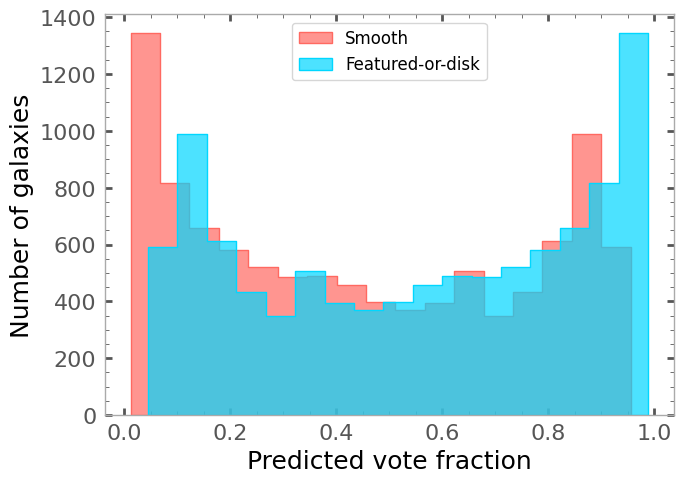

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.histplot(
    data=morph_df,
    x="smooth_or_featured_smooth_fraction",
    element="step",
    color="#ff6961",
    alpha=0.7,
    ax=ax,
    label="Smooth",
)
sns.histplot(
    data=morph_df,
    x="smooth_or_featured_featured_or_disk_fraction",
    element="step",
    color="#00D7FF",
    alpha=0.7,
    ax=ax,
    label="Featured-or-disk",
)

ax.set_xlabel("Predicted vote fraction", fontsize=18)
ax.set_ylabel("Number of galaxies", fontsize=18)
ax.tick_params(
    axis="both", which="major", right=True, top=True, labelsize=16, width=2, length=5
)
ax.tick_params(axis="both", which="minor", right=True, top=True, labelsize=16, length=3)
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.yaxis.set_minor_locator(AutoMinorLocator())

ax.legend(fontsize=12, loc="upper center")
ax.grid(False)

plt.tight_layout()
plt.show()

### 3.2 Selecting smooth, featured, and barred galaxies

As noted in the introduction, there is no unique threshold that separates smooth from featured-or-disk galaxies: a higher threshold gives a purer but less complete sample. Here we adopt `smooth_or_featured_smooth_fraction > 0.7` and `smooth_or_featured_featured_or_disk_fraction > 0.5` purely as an illustration; feel free to adapt them to your own science case. For barred galaxies, we will choose featured galaxies with `disk_edge_on_no_fraction > 0.5` and `bar_no_fraction < 0.5`.

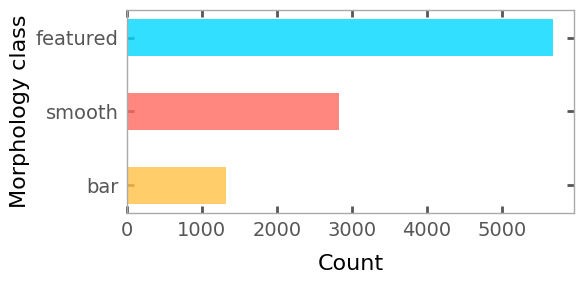

In [ ]:
morph_df["smooth_zb"] = np.where(
    morph_df["smooth_or_featured_smooth_fraction"] > 0.7, 1, np.nan
)
morph_df["featured_zb"] = np.where(
    morph_df["smooth_or_featured_featured_or_disk_fraction"] > 0.5, 1, np.nan
)

cond_bar = (
    (morph_df["featured_zb"] == 1)
    & (morph_df["disk_edge_on_no_fraction"] > 0.5)
    & (morph_df["bar_no_fraction"] < 0.5)
)

morph_df["bar_zb"] = np.where(cond_bar, 1, np.nan)

df_counts = (
    morph_df[["smooth_zb", "featured_zb", "bar_zb"]]
    .sum()
    .astype(int)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(6, 3))
colors = ["#ffc145", "#ff6961", "#00D7FF"]

ax.barh(
    df_counts.index.str.replace("_zb", ""),
    df_counts.values,
    height=0.5,
    color=colors,
    alpha=0.8,
)

ax.set_xlabel("Count", fontsize=16, labelpad=10)
ax.set_ylabel("Morphology class", fontsize=16)
ax.tick_params(
    axis="both", which="major", right=True, top=True, labelsize=14, width=2, length=5
)
ax.grid(False)

plt.tight_layout()
plt.show()

### 3.3 Visualising random examples for each class

We now fetch VIS mosaic cutouts for 5 random smooth, featured-or-disk, and barred galaxies in our sample, directly from the Datalabs data volume (same approach as `Cutouts.ipynb`, adapted here to the WIDE survey mosaics). For any more advanced or batch cutout workflow (e.g. cutouts for thousands of sources, multiple filters, ...), see the dedicated [Cutouts.ipynb](~/Notebooks/PDR/DR1/Cutouts.ipynb) notebook.

INFO: Query finished. [astroquery.utils.tap.core]


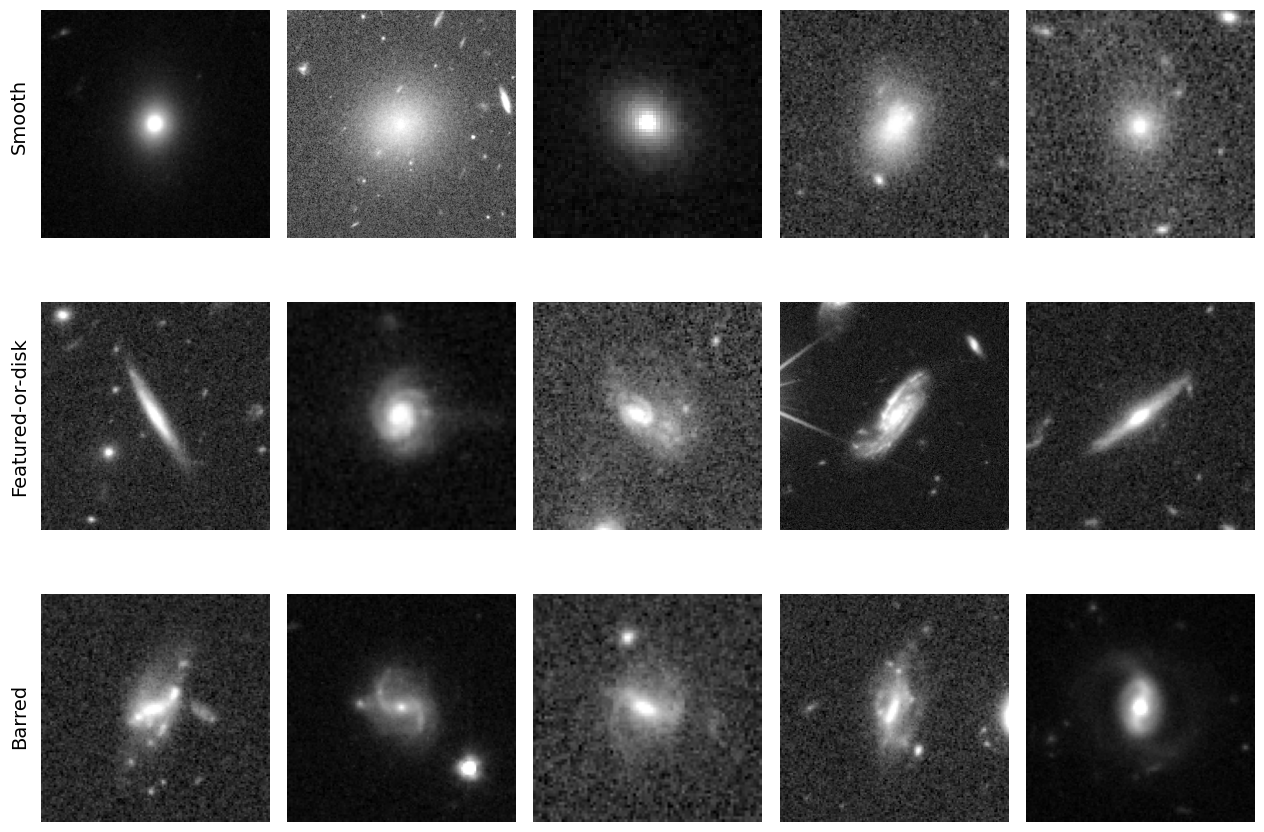

In [ ]:
# Select random examples of each class
N = 5
rng_seed = 42

is_smooth = morph_df["smooth_zb"] == 1
is_featured = morph_df["featured_zb"] == 1
is_barred = morph_df["bar_zb"] == 1

sel_smooth = (
    morph_df[is_smooth].sample(N, random_state=rng_seed).assign(example_class="smooth")
)
sel_featured = (
    morph_df[is_featured & ~is_barred]
    .sample(N, random_state=rng_seed)
    .assign(example_class="featured")
)
sel_barred = (
    morph_df[is_barred].sample(N, random_state=rng_seed).assign(example_class="barred")
)

examples = pd.concat([sel_smooth, sel_featured, sel_barred]).reset_index(drop=True)

examples["cutout_size"] = 1.4 * 0.1 * examples["kron_radius"]
tiles_str = ",".join(str(int(t)) for t in examples["tile_index"].unique())

query = f"""SELECT tile_index, datalabs_path, file_name

FROM dr1.mosaic_product

WHERE instrument_name = 'VIS' AND processing_mode = 'WIDE'
AND tile_index IN ({tiles_str})"""

mosaics = (
    Euclid.launch_job_async(query)
    .get_results()
    .to_pandas()
    .drop_duplicates("tile_index")
    .set_index("tile_index")
)

# Generate the cutouts, caching one open FITS file per tile
hdul_cache, cutout_list, labels = {}, [], []

for _, row in examples.iterrows():
    tile = int(row.tile_index)
    if tile not in hdul_cache:
        mosaic = mosaics.loc[tile]
        file_path = f"{mosaic.datalabs_path}/{mosaic.file_name}"
        hdul_cache[tile] = fits.open(file_path)

    hdul = hdul_cache[tile]
    coord = SkyCoord(row.right_ascension * u.deg, row.declination * u.deg)
    cutout = Cutout2D(
        data=hdul[0].data,
        position=coord,
        size=row.cutout_size * u.arcsec,
        wcs=wcs.WCS(hdul[0].header),
    )

    cutout_list.append(cutout)
    labels.append(row.example_class)

for hdul in hdul_cache.values():
    hdul.close()

# Plot the cutouts
fig, axes = plt.subplots(3, N, figsize=(2.5 * N, 9))

for ax, cutout, label in zip(axes.flat, cutout_list, labels):
    ax.imshow(
        cutout.data,
        cmap="gray",
        origin="lower",
        norm=ImageNormalize(
            cutout.data, interval=PercentileInterval(99.5), stretch=AsinhStretch()
        ),
    )
    ax.axis("off")

y = 5 / 6
for ax_row, label in zip(axes, ["Smooth", "Featured-or-disk", "Barred"]):
    fig.text(-0.01, y, label, rotation=90, va="center", fontsize=14)
    y -= 1 / 3

plt.tight_layout()
plt.show()

### 3.4 Visualising most confident examples for each class

INFO: Query finished. [astroquery.utils.tap.core]


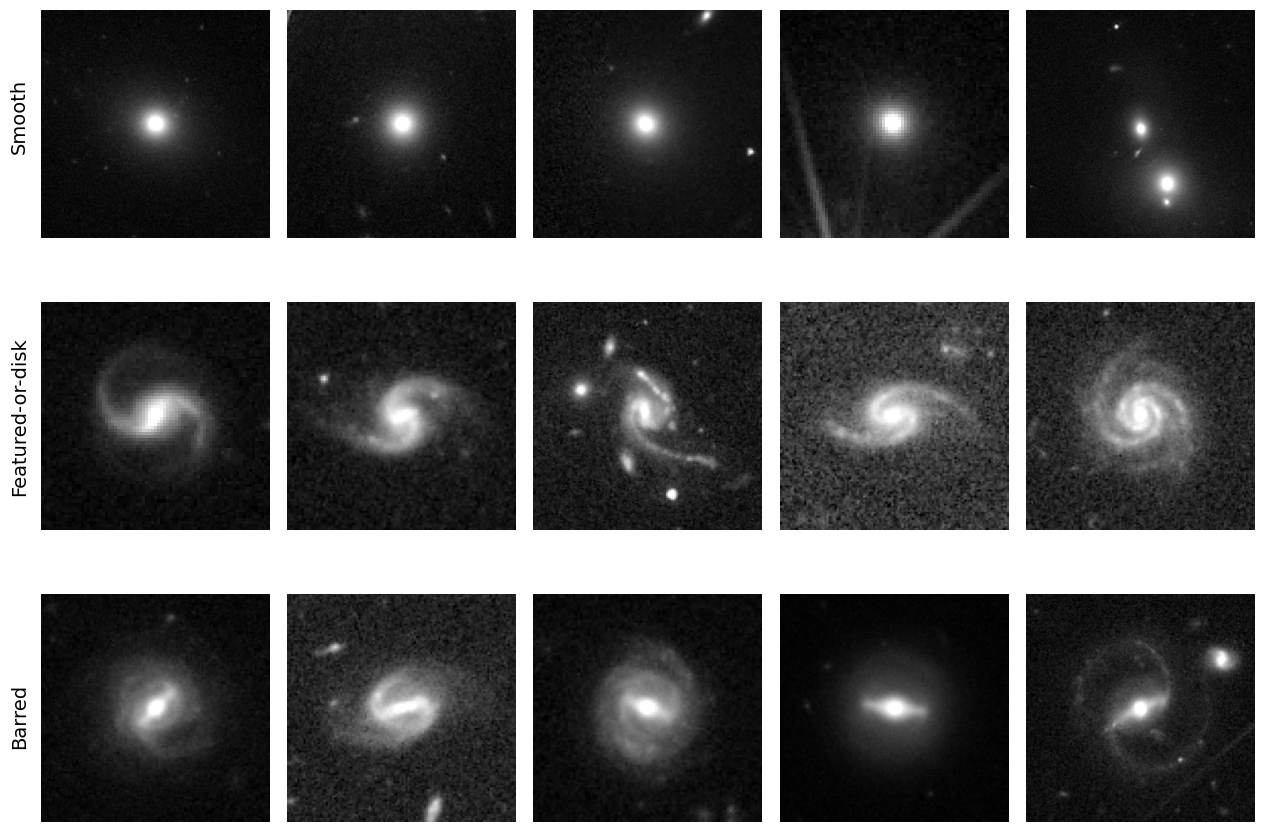

In [ ]:
# Select the most confident examples
N = 5

top_smooth = (
    morph_df.sort_values("smooth_or_featured_smooth_fraction", ascending=False)
    .head(N)
    .assign(example_class="smooth")
)

top_featured = (
    morph_df.sort_values(
        "smooth_or_featured_featured_or_disk_fraction", ascending=False
    )
    .head(N)
    .assign(example_class="featured")
)

top_barred = (
    morph_df.sort_values("bar_no_fraction", ascending=True)
    .head(N)
    .assign(example_class="barred")
)

examples = pd.concat([top_smooth, top_featured, top_barred]).reset_index(drop=True)

examples["cutout_size"] = 1.2 * 0.1 * examples["kron_radius"]
tiles_str = ",".join(str(int(t)) for t in examples["tile_index"].unique())

query = f"""SELECT tile_index, datalabs_path, file_name

FROM dr1.mosaic_product

WHERE instrument_name = 'VIS' AND processing_mode = 'WIDE'
AND tile_index IN ({tiles_str})"""

mosaics = (
    Euclid.launch_job_async(query)
    .get_results()
    .to_pandas()
    .drop_duplicates("tile_index")
    .set_index("tile_index")
)

# Generate the cutouts, caching one open FITS file per tile
hdul_cache, cutout_list, labels = {}, [], []

for _, row in examples.iterrows():
    tile = int(row.tile_index)
    if tile not in hdul_cache:
        mosaic = mosaics.loc[tile]
        file_path = f"{mosaic.datalabs_path}/{mosaic.file_name}"
        hdul_cache[tile] = fits.open(file_path)

    hdul = hdul_cache[tile]
    coord = SkyCoord(row.right_ascension * u.deg, row.declination * u.deg)
    cutout = Cutout2D(
        data=hdul[0].data,
        position=coord,
        size=row.cutout_size * u.arcsec,
        wcs=wcs.WCS(hdul[0].header),
    )

    cutout_list.append(cutout)
    labels.append(row.example_class)

for hdul in hdul_cache.values():
    hdul.close()

# Plot the cutouts
fig, axes = plt.subplots(3, N, figsize=(2.5 * N, 9))

for ax, cutout, label in zip(axes.flat, cutout_list, labels):
    ax.imshow(
        cutout.data,
        cmap="gray",
        origin="lower",
        norm=ImageNormalize(
            cutout.data, interval=PercentileInterval(99.5), stretch=AsinhStretch()
        ),
    )
    ax.axis("off")

y = 5 / 6
for ax_row, label in zip(axes, ["Smooth", "Featured-or-disk", "Barred"]):
    fig.text(-0.01, y, label, rotation=90, va="center", fontsize=14)
    y -= 1 / 3

plt.tight_layout()
plt.show()

## 4. Going further: Zoobot

### 4.1 Installing Zoobot

[Zoobot](https://github.com/mwalmsley/zoobot) is distributed as the `zoobot` package on PyPI (requires Python &ge; 3.9). Install it with:

```bash
pip install "zoobot[pytorch]"
```

This installs Zoobot together with PyTorch and the pretrained-model utilities. See the [documentation homepage](https://zoobot.readthedocs.io/) for full details, including GPU-specific instructions.

In [ ]:
# Uncomment to install Zoobot (not required to run Sections 1-3 of this notebook)
# !pip install "zoobot[pytorch]"

### 4.2 Using and adapting the models

Once installed, Zoobot can be used in two main ways:

* **Apply a pretrained model directly**, or as a fixed feature extractor for your own downstream task. The full list of pretrained checkpoints (including the model used to produce this DR1 morphology catalogue) is available on the [pretrained models page](https://zoobot.readthedocs.io/en/latest/pretrained_models.html).
* **Fine-tune Zoobot on your own labelled galaxies**, e.g. to add a new question that is not part of the Galaxy Zoo tree. A minimal example:

```python
from galaxy_datasets.pytorch.galaxy_datamodule import CatalogDataModule
from zoobot.pytorch.training import finetune

labelled_df = pd.read_csv('/your/path/some_labelled_galaxies.csv')
datamodule  = CatalogDataModule(label_cols=['ring'], catalog=labelled_df, batch_size=32)

model   = finetune.FinetuneableZoobotClassifier(name='hf_hub:mwalmsley/zoobot-encoder-convnext_nano', label_col='ring', num_classes=2)

trainer = finetune.get_trainer(save_dir,max_epochs=100)
trainer.fit(model, datamodule)
```

Further worked examples (including how to predict on a new catalogue with `zoobot.pytorch.predictions.predict_on_catalog`) are available in the [`examples/finetuning/`](https://github.com/mwalmsley/zoobot/tree/main/examples/finetuning) folder of the Zoobot repository, and in the [full documentation](https://zoobot.readthedocs.io/).

## References

If you use the Euclid DR1 morphology catalogue and/or Zoobot in your work, please cite:

* [Euclid Collaboration: Walmsley et al. 2026](https://scixplorer.org/abs/2026A%26A...711A...9E/abstract) - describing the visual morphology catalogue methodology (Q1; the same pipeline was used to produce the DR1 catalogue used in this notebook - **check for an updated DR1-specific reference if it becomes available**).
* [Walmsley et al. 2023](https://joss.theoj.org/papers/10.21105/joss.05312) - the Zoobot software paper (JOSS).